# Week 2 Day 3 — Exploratory Data Analysis

Generated for Cynaris Solutions — Week 2. Run cells from top to bottom.


## 1. Load and profile the dataset

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path(__file__).resolve().parent
# If running from another directory, adjust ROOT to your repository root.
DATA = ROOT / "data" / "week-2" / "raw"
OUT = ROOT / "reports" / "week-2"
OUT.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(DATA / "sunrise_resource_utilisation.csv")
df["date"] = pd.to_datetime(df["date"], errors="coerce")
sns.set_theme(style="whitegrid", palette="deep")
display(df.head())
print("Shape:", df.shape)


## 2. Data quality profile

In [ ]:
profile = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True)
})
display(profile)
print("Duplicate rows:", df.duplicated().sum())
display(df.describe(include="all").T)


## 3. Numeric distributions

In [ ]:
numeric = df.select_dtypes(include="number")
numeric.hist(figsize=(14, 10), bins=20, edgecolor="black")
plt.suptitle("Distributions of Numeric Resource Metrics")
plt.tight_layout(); plt.show()


## 4. Correlation heatmap

In [ ]:
plt.figure(figsize=(11, 8))
sns.heatmap(numeric.corr(), annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation Heatmap — Hospital Resource Metrics")
plt.tight_layout(); plt.show()


## 5. Outlier review using the IQR rule

In [ ]:
outlier_rows = []
for col in numeric.columns:
    q1, q3 = numeric[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = ((numeric[col] < low) | (numeric[col] > high)).sum()
    outlier_rows.append({"column": col, "lower_bound": low, "upper_bound": high, "potential_outliers": int(count)})
display(pd.DataFrame(outlier_rows))


## 6. Evidence-based business insights
Run this section and use its output plus charts to write five findings. Do not invent causal explanations.

In [ ]:
print("Department average waiting time:")
display(df.groupby("department")["avg_patient_wait_mins"].mean().sort_values(ascending=False))
print("Hospital average bed occupancy:")
display((df.assign(occupancy_pct=100*df.occupied_beds/df.total_beds.replace(0, np.nan))
           .groupby("hospital")["occupancy_pct"].mean().sort_values(ascending=False)))
print("Surgery completion summary:")
display((df.assign(completion_pct=100*df.surgeries_completed/df.surgeries_scheduled.replace(0, np.nan))
           .groupby("department")["completion_pct"].mean().sort_values(ascending=False)))
print("Staff attendance averages:")
display(df[["doctor_attendance_pct", "nurse_attendance_pct"]].mean())
print("Readmission count by department:")
display(df.groupby("department")["readmission_count"].mean().sort_values(ascending=False))


DATASET OVERVIEW
Total records: 400
Total columns: 14

BED CAPACITY INVESTIGATION
Total records: 400
Violation records: 175
Violation percentage: 43.75 %

SAMPLE VIOLATION RECORDS


,record_id,hospital,department,total_beds,occupied_beds
5,RES-0006,Sunrise Main Campus,Orthopaedics,29,39
7,RES-0008,Sunrise South,IPD,37,51
8,RES-0009,Sunrise Main Campus,OPD,12,76
10,RES-0011,Sunrise Main Campus,Emergency,37,48
12,RES-0013,Sunrise North,OPD,35,37
13,RES-0014,Sunrise Main Campus,Orthopaedics,52,97
19,RES-0020,Sunrise East,Surgery,35,59
22,RES-0023,Sunrise North,Radiology,45,91
26,RES-0027,Sunrise North,Pharmacy,70,91
28,RES-0029,Sunrise North,OPD,41,65



VIOLATIONS BY HOSPITAL AND DEPARTMENT


,hospital,department,violation_count
2,Sunrise East,IPD,10
13,Sunrise Main Campus,OPD,10
15,Sunrise Main Campus,Pharmacy,9
24,Sunrise North,Pharmacy,7
35,Sunrise South,Surgery,7
32,Sunrise South,Orthopaedics,7
23,Sunrise North,Orthopaedics,7
29,Sunrise South,IPD,6
22,Sunrise North,OPD,6
25,Sunrise North,Radiology,6



TOP 20 OCCUPANCY PERCENTAGES


,hospital,department,total_beds,occupied_beds,occupancy_percentage
103,Sunrise North,Radiology,10,97,970.000000
231,Sunrise South,Surgery,11,104,945.454545
127,Sunrise Main Campus,Pharmacy,10,88,880.000000
289,Sunrise South,OPD,11,93,845.454545
239,Sunrise North,OPD,14,105,750.000000
114,Sunrise East,IPD,11,72,654.545455
8,Sunrise Main Campus,OPD,12,76,633.333333
359,Sunrise Main Campus,OPD,13,78,600.000000
297,Sunrise Main Campus,OPD,18,96,533.333333
166,Sunrise South,Lab,20,104,520.000000


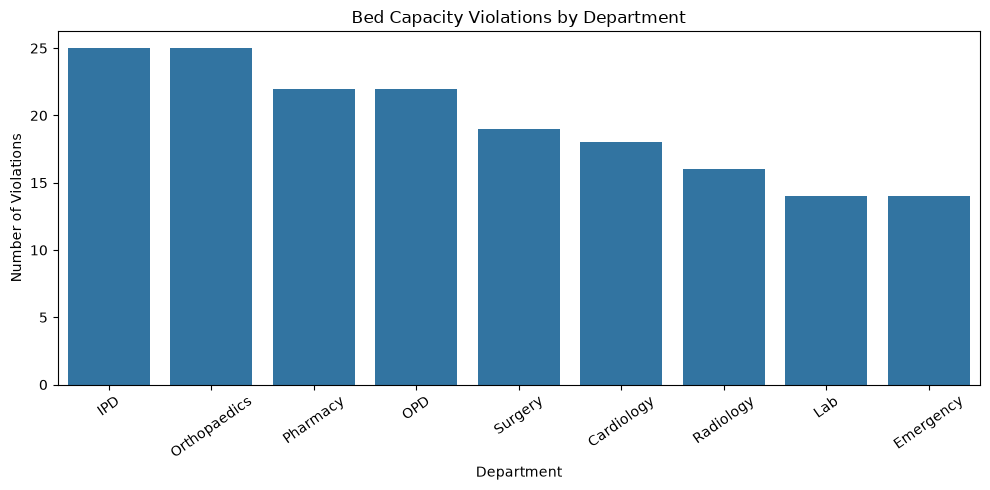


ICU CAPACITY INVESTIGATION
ICU capacity violations: 175

FINAL SUMMARY
Total records: 400
Bed capacity violations: 175
Violation rate: 43.75 %
ICU capacity violations: 175

IMPORTANT: No original records have been deleted, capped, or modified.
Business-rule confirmation is required before correcting these records.


In [1]:

# ============================================================
# BED CAPACITY VIOLATION INVESTIGATION
# Cynaris Internship - Week 2
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Locate the project dataset
current = Path.cwd()
data_file = None

for folder in [current, *current.parents]:
    candidate = (
        folder / "data" / "week-2" / "raw"
        / "sunrise_resource_utilisation.csv"
    )
    if candidate.exists():
        data_file = candidate
        break

if data_file is None:
    raise FileNotFoundError(
        "Could not find sunrise_resource_utilisation.csv. "
        "Check data/week-2/raw/"
    )

# 2. Load the original dataset
df = pd.read_csv(data_file)

print("DATASET OVERVIEW")
print("Total records:", len(df))
print("Total columns:", len(df.columns))

# 3. Identify bed capacity violations
violations = df[
    df["occupied_beds"] > df["total_beds"]
].copy()

print("\nBED CAPACITY INVESTIGATION")
print("Total records:", len(df))
print("Violation records:", len(violations))

violation_percentage = (
    len(violations) / len(df) * 100
)

print(
    "Violation percentage:",
    round(violation_percentage, 2), "%"
)

# 4. Display sample violating records
print("\nSAMPLE VIOLATION RECORDS")

display(
    violations[
        [
            "record_id",
            "hospital",
            "department",
            "total_beds",
            "occupied_beds"
        ]
    ].head(20)
)

# 5. Group violations by hospital and department
print("\nVIOLATIONS BY HOSPITAL AND DEPARTMENT")

violation_summary = (
    violations
    .groupby(["hospital", "department"])
    .size()
    .reset_index(name="violation_count")
    .sort_values(
        "violation_count",
        ascending=False
    )
)

display(violation_summary)

# 6. Calculate occupancy percentage
df["occupancy_percentage"] = (
    df["occupied_beds"]
    / df["total_beds"].replace(0, np.nan)
) * 100

print("\nTOP 20 OCCUPANCY PERCENTAGES")

display(
    df[
        [
            "hospital",
            "department",
            "total_beds",
            "occupied_beds",
            "occupancy_percentage"
        ]
    ]
    .sort_values(
        "occupancy_percentage",
        ascending=False
    )
    .head(20)
)

# 7. Visualise violations by department
if not violation_summary.empty:

    department_violations = (
        violations.groupby("department")
        .size()
        .sort_values(ascending=False)
        .reset_index(name="violations")
    )

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=department_violations,
        x="department",
        y="violations"
    )

    plt.title(
        "Bed Capacity Violations by Department"
    )
    plt.xlabel("Department")
    plt.ylabel("Number of Violations")
    plt.xticks(rotation=35)
    plt.tight_layout()
    plt.show()

# 8. Check ICU bed capacity separately
icu_violations = df[
    df["icu_beds_occupied"] > df["icu_beds_total"]
]

print("\nICU CAPACITY INVESTIGATION")
print("ICU capacity violations:", len(icu_violations))

# 9. Final investigation summary
print("\nFINAL SUMMARY")
print("Total records:", len(df))
print("Bed capacity violations:", len(violations))
print(
    "Violation rate:",
    round(violation_percentage, 2), "%"
)
print("ICU capacity violations:", len(icu_violations))

print(
    "\nIMPORTANT: No original records have been "
    "deleted, capped, or modified."
)
print(
    "Business-rule confirmation is required "
    "before correcting these records."
)


In [2]:

# ============================================================
# DEEP INVESTIGATION: BED AND ICU CAPACITY
# ============================================================

# 1. Compare bed and ICU violations
bed_violations = df["occupied_beds"] > df["total_beds"]

icu_violations = (
    df["icu_beds_occupied"] > df["icu_beds_total"]
)

print("BED AND ICU COMPARISON")
print("Bed violations:", bed_violations.sum())
print("ICU violations:", icu_violations.sum())

print(
    "Both violations in the same records:",
    (bed_violations & icu_violations).sum()
)

print(
    "Only bed violations:",
    (bed_violations & ~icu_violations).sum()
)

print(
    "Only ICU violations:",
    (~bed_violations & icu_violations).sum()
)

# 2. Compare the actual values
print("\nBED AND ICU SAMPLE VALUES")

display(
    df.loc[
        bed_violations | icu_violations,
        [
            "record_id",
            "hospital",
            "department",
            "total_beds",
            "occupied_beds",
            "icu_beds_total",
            "icu_beds_occupied"
        ]
    ].head(25)
)

# 3. Check whether the two occupied-bed columns
# contain identical values
print("\nCOLUMN COMPARISON")

print(
    "Occupied beds equal ICU occupied beds:",
    df["occupied_beds"].equals(
        df["icu_beds_occupied"]
    )
)

# 4. Check whether the two capacity columns
# contain identical values
print(
    "Total beds equal ICU total beds:",
    df["total_beds"].equals(
        df["icu_beds_total"]
    )
)

# 5. Compare correlations
print("\nCORRELATION BETWEEN BED METRICS")

display(
    df[
        [
            "total_beds",
            "occupied_beds",
            "icu_beds_total",
            "icu_beds_occupied"
        ]
    ].corr()
)

# 6. Final diagnostic
print("\nDIAGNOSTIC COMPLETE")
print("No original data has been changed.")


BED AND ICU COMPARISON
Bed violations: 175
ICU violations: 175
Both violations in the same records: 84
Only bed violations: 91
Only ICU violations: 91

BED AND ICU SAMPLE VALUES


,record_id,hospital,department,total_beds,occupied_beds,icu_beds_total,icu_beds_occupied
2,RES-0003,Sunrise East,Orthopaedics,60,34,13,26
3,RES-0004,Sunrise Main Campus,Emergency,105,88,10,14
5,RES-0006,Sunrise Main Campus,Orthopaedics,29,39,19,24
6,RES-0007,Sunrise East,Emergency,84,25,14,15
7,RES-0008,Sunrise South,IPD,37,51,20,12
8,RES-0009,Sunrise Main Campus,OPD,12,76,10,23
10,RES-0011,Sunrise Main Campus,Emergency,37,48,16,17
12,RES-0013,Sunrise North,OPD,35,37,22,15
13,RES-0014,Sunrise Main Campus,Orthopaedics,52,97,11,7
16,RES-0017,Sunrise South,Surgery,57,27,5,14



COLUMN COMPARISON
Occupied beds equal ICU occupied beds: False
Total beds equal ICU total beds: False

CORRELATION BETWEEN BED METRICS


,total_beds,occupied_beds,icu_beds_total,icu_beds_occupied
total_beds,1.000000,0.101229,0.007572,-0.016309
occupied_beds,0.101229,1.000000,-0.066877,0.078752
icu_beds_total,0.007572,-0.066877,1.000000,-0.060877
icu_beds_occupied,-0.016309,0.078752,-0.060877,1.000000



DIAGNOSTIC COMPLETE
No original data has been changed.


In [3]:

# ============================================================
# ADDITIONAL BED AND ICU CONSISTENCY VALIDATION
# ============================================================

# Rule 1: ICU capacity should not exceed total bed capacity
rule1 = df["icu_beds_total"] <= df["total_beds"]

# Rule 2: ICU occupied beds should not exceed ICU capacity
rule2 = (
    df["icu_beds_occupied"] <= df["icu_beds_total"]
)

# Rule 3: ICU occupied beds should not exceed
# total occupied beds (assuming total includes ICU)
rule3 = (
    df["icu_beds_occupied"] <= df["occupied_beds"]
)

# Display validation results
results = pd.DataFrame({
    "Business Rule": [
        "ICU capacity <= Total bed capacity",
        "ICU occupied beds <= ICU capacity",
        "ICU occupied beds <= Total occupied beds"
    ],
    "Passed Records": [
        int(rule1.sum()),
        int(rule2.sum()),
        int(rule3.sum())
    ],
    "Failed Records": [
        int((~rule1).sum()),
        int((~rule2).sum()),
        int((~rule3).sum())
    ]
})

print("ADDITIONAL BUSINESS RULE VALIDATION")
display(results)

# Show records violating at least one additional rule
additional_violations = df[
    ~(rule1 & rule2 & rule3)
].copy()

print(
    "\nRecords violating at least one additional rule:",
    len(additional_violations)
)

display(
    additional_violations[
        [
            "record_id",
            "hospital",
            "department",
            "total_beds",
            "occupied_beds",
            "icu_beds_total",
            "icu_beds_occupied"
        ]
    ].head(20)
)

print("\nOriginal dataset remains unchanged.")


ADDITIONAL BUSINESS RULE VALIDATION


,Business Rule,Passed Records,Failed Records
0,ICU capacity <= Total bed capacity,369,31
1,ICU occupied beds <= ICU capacity,225,175
2,ICU occupied beds <= Total occupied beds,365,35



Records violating at least one additional rule: 214


,record_id,hospital,department,total_beds,occupied_beds,icu_beds_total,icu_beds_occupied
2,RES-0003,Sunrise East,Orthopaedics,60,34,13,26
3,RES-0004,Sunrise Main Campus,Emergency,105,88,10,14
5,RES-0006,Sunrise Main Campus,Orthopaedics,29,39,19,24
6,RES-0007,Sunrise East,Emergency,84,25,14,15
8,RES-0009,Sunrise Main Campus,OPD,12,76,10,23
9,RES-0010,Sunrise East,OPD,71,6,19,11
10,RES-0011,Sunrise Main Campus,Emergency,37,48,16,17
15,RES-0016,Sunrise South,Pharmacy,111,6,18,16
16,RES-0017,Sunrise South,Surgery,57,27,5,14
17,RES-0018,Sunrise East,Radiology,114,7,14,13



Original dataset remains unchanged.



## Business Insight — ICU and Hospital Capacity Consistency

Further investigation identified three additional potential
data-quality issues across 400 hospital resource records.

1. 31 records have ICU capacity greater than total bed capacity.
2. 175 records have ICU occupied beds greater than ICU capacity.
3. 35 records have ICU occupied beds greater than total occupied beds.

These findings indicate potential inconsistencies between
hospital and ICU resource measurements.

The business rules require confirmation from the data owner,
particularly whether total occupied beds includes ICU occupancy.

No original records have been deleted or modified.
